# Agreement diagnostics: weighting, uncertainty, and category alignment

This extension uses the **original five-run modal classifications**; it makes no API calls and does not change any labels, regressions, or MAE estimates. It replaces manuscript Figure 1 with two agreement panels evaluated on the same 1,039 validation claims as MAE, and generates a compact agreement appendix.

Four estimands are kept separate: (1) all 4,690 descriptions, equal weight; (2) the 996 validation descriptions, equal weight; (3) validation claims, using each description's claim count (total 1,039); and (4) validation paid loss, using each description's total validation loss. Loss weighting is an **ex post diagnostic**, not information assumed available when routing a reported claim.

We report raw exact disagreement, quadratic-weighted Cohen's kappa, and mean absolute ordinal distance (MAD). Pointwise percentile intervals resample description clusters 2,000 times, keeping repeated claims and their losses together and recomputing all denominators and kappa marginals. Intervals condition on the saved modal labels: they do not capture inference reruns, shared-request dependence, GLM refitting, or provider changes.

Two secondary diagnostics distinguish systematic scale use from ordering differences. An integer shift and model-specific marginal mid-percentile mappings are learned **only from training descriptions absent from validation**, without using any loss values. We then assess the fixed mappings on validation. Raw labels remain the primary record of named category assignments. No fitted GLM is recalibrated for this diagnostic.

The fixed-input section establishes a matched same-model reference using Experiment 2: five saved reruns of genuinely identical batched prompts. It compares quadratic kappa, exact agreement, and ordinal distance within and between models, without collecting any new labels. Its intervals resample the 50 fixed batches to retain dependence among descriptions submitted together.

Generated prose and tables update marked sections directly in `paper_naaj/manuscript_body.tex` and the single `paper_naaj/appendix.tex`. No separate TeX fragments are written. Analytical artifact manifests cover the notebook outputs; the shared manuscript sources are versioned separately.

The compact primary appendix is rendered by `paper_reporting.py`; complete supporting outputs are indexed in `SUPPLEMENT.md`.

**Paper coverage:** §§4.2 and 4.4, Figure 1, and Appendix A.4, A.6–A.7 (Tables A6, A10–A13).

Use the pinned environment in [README.md](README.md#run-the-analysis). Run cells from top to bottom; saved inference caches allow reproduction without API keys or new requests.


In [1]:
from pathlib import Path
from itertools import combinations
from io import BytesIO
import hashlib, json, platform
import numpy as np
import pandas as pd
import scipy
from scipy import sparse
from scipy.stats import spearmanr
from sklearn.metrics import cohen_kappa_score
import sklearn
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from IPython.display import display, Image

ROOT = Path.cwd()
assert (ROOT / 'paper_naaj').is_dir(), 'Execute from the repository root.'
import sys
sys.path.insert(0, str(ROOT))
from manuscript_sections import update_section
from paper_reporting import write_primary_appendix
OUT = ROOT / 'tables/agreement_diagnostics'
OUT.mkdir(parents=True, exist_ok=True)
PAPER = ROOT / 'paper_naaj'
N_BOOT = 2000
SEED = 20261105
EXPECTED = {
    'data/processed/claims.csv': '606128c7d2dd87d98a4f875a7e9b2c9bc63cc0e76a166794d106f6513c03fe76',
    'data/results/modal_classifications.csv': '56cd7b46d4ca7fa9a4dec13414a6f5c5dbc7db353e7e969d10bddda1382dec86',
    'tables/pairwise_equivalence.csv': 'feb120c1c16e211629e4930c320a8575e47ce9194523bbb3cd166dcfba4a4503',
    'tables/model_roster.csv': '0df0c57a3b2a9ef9d908ac7abaad3a640dae6013bfe774231b8271bb8737b3cf',
}
EXPECTED.update({
    'data/results/classifications_fixed.csv': 'ac6ff0f05a47e89da703e761aadd009221b8bfa85c70d535467f1e7399b1f943',
    'data/results/fixed_batch_manifest.csv': 'e149fd21f2c7f97003619d300cc44d107fb4990186879f0742c8c06c47dfaf7e',
    'tables/fixed_batch_prompt_audit.csv': 'aba74e768b5f2412b2218e269be3f66ef8218501d246d1b5f2e197962aefcfdb',
})
input_manifest = []
def read_frozen(relative):
    payload = (ROOT / relative).read_bytes()
    digest = hashlib.sha256(payload).hexdigest()
    assert digest == EXPECTED[relative], f'Frozen input changed: {relative}'
    input_manifest.append(dict(path=relative, sha256=digest, source=relative))
    return pd.read_csv(BytesIO(payload))

claims = read_frozen('data/processed/claims.csv')
modal = read_frozen('data/results/modal_classifications.csv')
pairs = read_frozen('tables/pairwise_equivalence.csv')
models = read_frozen('tables/model_roster.csv')['model'].tolist()
short = dict(zip(models, ['GPT', 'Gemini', 'Kimi', 'DeepSeek', 'Qwen', 'GLM']))
pairs.insert(0, 'pair_id', np.arange(1, len(pairs)+1))
labels = modal.pivot(index='description_id', columns='model', values='modal_value').reindex(columns=models).sort_index()
assert labels.shape == (4690, 6) and labels.notna().all().all()
assert labels.isin(range(1, 6)).all().all()
valid = claims.loc[claims['split'].eq('validation')].copy()
valid_weights = valid.groupby('description_id').agg(claim_count=('Loss', 'size'), loss_total=('Loss', 'sum')).sort_index()
calibration_ids = sorted(set(claims.loc[claims['split'].eq('train'), 'description_id']) - set(valid_weights.index))
calibration = labels.loc[calibration_ids]
assert len(valid) == 1039 and len(valid_weights) == 996 and len(calibration) == 3694
assert valid['Loss'].gt(0).all()
assert not set(calibration_ids).intersection(valid_weights.index)
pd.DataFrame(input_manifest).to_csv(OUT / 'input_manifest.csv', index=False)
display(pd.DataFrame([
    dict(population='Full descriptions', descriptions=len(labels), total_weight=len(labels)),
    dict(population='Validation descriptions', descriptions=len(valid_weights), total_weight=len(valid_weights)),
    dict(population='Validation claims', descriptions=len(valid_weights), total_weight=len(valid)),
    dict(population='Validation loss ($)', descriptions=len(valid_weights), total_weight=valid['Loss'].sum()),
    dict(population='Training-only alignment calibration', descriptions=len(calibration), total_weight=len(calibration)),
]))


,population,descriptions,total_weight
0,Full descriptions,4690,4690.00
1,Validation descriptions,996,996.00
2,Validation claims,996,1039.00
3,Validation loss ($),996,22326419.53
4,Training-only alignment calibration,3694,3694.00


## Metrics and training-only alignment

For normalized contingency table $p_{kl}$, raw disagreement is $1-\sum_k p_{kk}$ and MAD is $\sum_{kl}p_{kl}|k-l|$. With $d_{kl}=(k-l)^2/16$, quadratic kappa is $1-\sum p_{kl}d_{kl}/\sum p_{k+}p_{+l}d_{kl}$. All marginals use the same population weights as observed agreement.

For each pair A, B, choose $\delta\in\{-4,\ldots,4\}$ minimizing training-only mean $|L_A-(L_B+\delta)|$; ties choose smallest $|\delta|$, then smaller signed shift. No clipping at the scale endpoints is permitted. Separately, each model's training-only marginal mapping is $u_m(k)=P_{\rm tr}(L_m<k)+P_{\rm tr}(L_m=k)/2$. Mean absolute differences of these scores are reported in percentile points. Weighted rank correlation is the Pearson correlation of evaluation-population marginal mid-ranks; with equal or integer claim weights it equals ordinary tied-rank Spearman correlation on the corresponding records.

The illustrative sequences `[1,2,3,4]` and `[2,3,4,5]` have 100% raw disagreement but zero disagreement after a learned shift of −1, identical marginal mid-percentiles, and rank correlation 1. Neither raw disagreement nor an aligned diagnostic alone describes all aspects of interchangeability.

**Reports:** §3.3 and Appendix A.6; supplementary training-only alignment.


In [2]:
LEVELS = np.arange(1, 6)
DISTANCE = np.abs(LEVELS[:, None] - LEVELS[None, :])
QUADRATIC = DISTANCE**2 / 16
RAW_DIFFERENT = (DISTANCE > 0).astype(float)

def mid_cdf(values, weights=None):
    counts = np.bincount(np.asarray(values, int), weights=weights, minlength=6)[1:6]
    p = counts / counts.sum()
    return np.cumsum(p) - p/2

training_scores = {m: mid_cdf(calibration[m]) for m in models}
shift_rows = []
for p in pairs.itertuples():
    a, b = calibration[p.model_a].to_numpy(), calibration[p.model_b].to_numpy()
    shift = min(range(-4, 5), key=lambda s: (np.mean(np.abs(a-b-s)), abs(s), s))
    shift_rows.append(dict(pair_id=p.pair_id, model_a=p.model_a, model_b=p.model_b,
                           shift_b_to_a=shift, calibration_descriptions=len(calibration),
                           calibration_mean_b_minus_a=float(np.mean(b-a)),
                           calibration_raw_distance=float(np.mean(np.abs(a-b))),
                           calibration_aligned_distance=float(np.mean(np.abs(a-b-shift)))))
shifts = pd.DataFrame(shift_rows).set_index('pair_id', drop=False)
shifts.to_csv(OUT / 'training_alignment_parameters.csv', index=False)
pd.DataFrame(training_scores, index=LEVELS).rename_axis('category').to_csv(OUT / 'training_mid_percentile_maps.csv')

def contingency(a, b, weights):
    return np.bincount((np.asarray(a, int)-1)*5 + np.asarray(b, int)-1,
                       weights=np.asarray(weights, float), minlength=25).reshape(5, 5)

def metrics(c, shift=0, score_a=None, score_b=None):
    c = np.asarray(c, float)
    p = c / c.sum(axis=(-2, -1), keepdims=True)
    row, col = p.sum(axis=-1), p.sum(axis=-2)
    observed = np.sum(p * QUADRATIC, axis=(-2, -1))
    expected = np.einsum('...i,ij,...j->...', row, QUADRATIC, col)
    ra, rb = np.cumsum(row, axis=-1)-row/2, np.cumsum(col, axis=-1)-col/2
    ma, mb = np.sum(row*ra, axis=-1), np.sum(col*rb, axis=-1)
    va = np.sum(row*(ra-ma[..., None])**2, axis=-1)
    vb = np.sum(col*(rb-mb[..., None])**2, axis=-1)
    cross = np.einsum('...ij,...i,...j->...', p, ra, rb) - ma*mb
    aligned_distance = np.abs(LEVELS[:, None] - (LEVELS[None, :] + shift))
    with np.errstate(invalid='ignore', divide='ignore'):
        result = {
            'disagreement': np.sum(p * RAW_DIFFERENT, axis=(-2, -1)),
            'quadratic_kappa': 1 - observed / expected,
            'mean_ordinal_distance': np.sum(p * DISTANCE, axis=(-2, -1)),
            'two_plus': np.sum(p * (DISTANCE >= 2), axis=(-2, -1)),
            'mean_b_minus_a': np.sum(p * (LEVELS[None, :]-LEVELS[:, None]), axis=(-2, -1)),
            'aligned_disagreement': np.sum(p * (aligned_distance > 0), axis=(-2, -1)),
            'aligned_distance': np.sum(p * aligned_distance, axis=(-2, -1)),
            'rank_correlation': cross / np.sqrt(va*vb),
        }
    if score_a is not None:
        result['percentile_distance_pp'] = 100*np.sum(p*np.abs(score_a[:, None]-score_b[None, :]), axis=(-2, -1))
    return result

# Analytic checks for the reviewer's pure-shift example, exact agreement, and reversal.
toy_a, toy_b = np.arange(1, 5), np.arange(2, 6)
toy_shift = min(range(-4, 5), key=lambda s: (np.mean(abs(toy_a-toy_b-s)), abs(s), s))
toy = metrics(contingency(toy_a, toy_b, np.ones(4)), toy_shift, mid_cdf(toy_a), mid_cdf(toy_b))
assert toy_shift == -1 and toy['disagreement'] == 1 and toy['aligned_disagreement'] == 0
assert np.isclose(toy['rank_correlation'], 1) and toy['percentile_distance_pp'] == 0
assert np.isclose(metrics(np.eye(5))['quadratic_kappa'], 1)
assert np.isclose(metrics(np.fliplr(np.eye(5)))['quadratic_kappa'], -1)
display(shifts[['model_a','model_b','shift_b_to_a','calibration_mean_b_minus_a']])


,model_a,model_b,shift_b_to_a,calibration_mean_b_minus_a
pair_id,,,,
1,GPT-5.6 Sol,Gemini 3.1 Pro,0,-0.357607
2,GPT-5.6 Sol,Kimi K2.6,0,-0.218192
3,GPT-5.6 Sol,DeepSeek V4 Pro,0,-0.138332
4,GPT-5.6 Sol,Qwen3.5 397B,0,-0.299675
5,GPT-5.6 Sol,GLM-5.2,0,-0.019220
6,Gemini 3.1 Pro,Kimi K2.6,0,0.139415
7,Gemini 3.1 Pro,DeepSeek V4 Pro,0,0.219274
8,Gemini 3.1 Pro,Qwen3.5 397B,0,0.057932
9,Gemini 3.1 Pro,GLM-5.2,0,0.338387


## Description-clustered bootstrap

Each resample draws the same number of unique descriptions as in that population, with replacement. A sampled validation description contributes **all its validation claims** and their original losses. A sparse 25-cell contingency representation computes all 2,000 resampled tables without expanding repeated claims. The three validation estimands share the same draws, and all model pairs share draws within a population. Training alignment maps stay fixed in these conditional intervals. All intervals below are pointwise 95% intervals, without multiplicity adjustment.

**Reports:** Appendix A.6; Table A10 intervals.


In [3]:
population_specs = {
    'full_description': (labels, np.ones(len(labels))),
    'validation_description': (labels.loc[valid_weights.index], np.ones(len(valid_weights))),
    'validation_claim': (labels.loc[valid_weights.index], valid_weights['claim_count'].to_numpy()),
    'validation_loss': (labels.loc[valid_weights.index], valid_weights['loss_total'].to_numpy()),
}
rng = np.random.default_rng(SEED)
draws_full = rng.multinomial(len(labels), np.full(len(labels), 1/len(labels)), size=N_BOOT).astype(np.int16)
draws_valid = rng.multinomial(len(valid_weights), np.full(len(valid_weights), 1/len(valid_weights)), size=N_BOOT).astype(np.int16)
rows, audits = [], []
for scheme, (panel, weights) in population_specs.items():
    draws = draws_full if scheme == 'full_description' else draws_valid
    for pair in pairs.itertuples():
        a, b = panel[pair.model_a].to_numpy(int), panel[pair.model_b].to_numpy(int)
        cell_index = (a-1)*5+b-1
        counts = contingency(a, b, weights)
        shift = int(shifts.loc[pair.pair_id, 'shift_b_to_a'])
        scores = (training_scores[pair.model_a], training_scores[pair.model_b])
        point = metrics(counts, shift, *scores)
        assignment = sparse.csr_matrix((weights, (np.arange(len(panel)), cell_index)), shape=(len(panel), 25))
        resampled_counts = (assignment.T @ draws.T).T.reshape(N_BOOT, 5, 5)
        sampled = metrics(resampled_counts, shift, *scores)
        row = dict(pair_id=pair.pair_id, model_a=pair.model_a, model_b=pair.model_b,
                   scheme=scheme, descriptions=len(panel), total_weight=float(np.sum(weights)),
                   approximately_equivalent=pair.approximately_equivalent,
                   mae_difference_pct_baseline=pair.mae_difference_pct_baseline,
                   shift_b_to_a=shift)
        for name, value in point.items():
            assert np.isfinite(sampled[name]).all(), (scheme, pair.pair_id, name)
            row[name] = float(value)
            row[name+'_lo'], row[name+'_hi'] = np.quantile(sampled[name], [0.025, 0.975])
        rows.append(row)
        reference_kappa = cohen_kappa_score(a, b, labels=LEVELS, weights='quadratic', sample_weight=weights)
        assert np.isclose(reference_kappa, point['quadratic_kappa'], atol=1e-12)
        assert np.isclose(np.average(a != b, weights=weights), point['disagreement'])
        assert np.isclose(np.average(abs(a-b), weights=weights), point['mean_ordinal_distance'])
        if scheme == 'full_description':
            assert np.isclose(point['disagreement'], pair.disagreement_rate)
            assert np.isclose(point['quadratic_kappa'], pair.weighted_kappa)
            assert np.isclose(point['mean_ordinal_distance'], pair.between_model_distance)
            assert np.isclose(point['rank_correlation'], spearmanr(a, b).statistic)
        if scheme == 'validation_claim':
            ea = valid['description_id'].map(labels[pair.model_a]).to_numpy()
            eb = valid['description_id'].map(labels[pair.model_b]).to_numpy()
            assert np.isclose(np.mean(ea != eb), point['disagreement'])
            assert np.isclose(np.mean(abs(ea-eb)), point['mean_ordinal_distance'])
            assert np.isclose(point['rank_correlation'], spearmanr(ea, eb).statistic)
        # One literal resample independently checks sparse cluster aggregation.
        expanded = np.repeat(np.arange(len(panel)), draws[0])
        check = metrics(contingency(a[expanded], b[expanded], weights[expanded]), shift, *scores)
        for name, value in check.items():
            assert np.isclose(value, sampled[name][0], atol=1e-12), (scheme, name)
        audits.append(dict(scheme=scheme, pair_id=pair.pair_id, sklearn_kappa=True,
                           direct_weighted_metrics=True, literal_cluster_resample=True))
agreement = pd.DataFrame(rows)
assert len(agreement) == 60 and agreement['approximately_equivalent'].sum() == 24
agreement.to_csv(OUT / 'pairwise_agreement_with_intervals.csv', index=False)
pd.DataFrame(audits).to_csv(OUT / 'verification_checks.csv', index=False)
mean_rows = []
for scheme, (panel, weights) in population_specs.items():
    for model in models:
        mean_rows.append(dict(scheme=scheme, model=model, mean_ordinal_label=np.average(panel[model], weights=weights)))
pd.DataFrame(mean_rows).to_csv(OUT / 'mean_category_by_model.csv', index=False)
summary = agreement.groupby('scheme').agg(
    min_disagreement=('disagreement','min'), max_disagreement=('disagreement','max'),
    min_kappa=('quadratic_kappa','min'), max_kappa=('quadratic_kappa','max'),
    min_distance=('mean_ordinal_distance','min'), max_distance=('mean_ordinal_distance','max'),
    min_rank=('rank_correlation','min'), max_rank=('rank_correlation','max'),
    min_percentile_distance=('percentile_distance_pp','min'), max_percentile_distance=('percentile_distance_pp','max'))
summary.to_csv(OUT / 'summary_ranges.csv')
display(summary.round(4))
display(agreement.loc[agreement.scheme.eq('validation_claim') & agreement.approximately_equivalent,
                      ['model_a','model_b','disagreement','disagreement_lo','disagreement_hi','quadratic_kappa','mean_ordinal_distance','rank_correlation','percentile_distance_pp']].round(4))
del draws_full, draws_valid, draws, resampled_counts


,min_disagreement,max_disagreement,min_kappa,max_kappa,min_distance,max_distance,min_rank,max_rank,min_percentile_distance,max_percentile_distance
scheme,,,,,,,,,,
full_description,0.1994,0.4090,0.6652,0.7880,0.2013,0.4132,0.7344,0.8075,8.2964,16.6755
validation_claim,0.2146,0.4976,0.6681,0.7895,0.2146,0.4995,0.7490,0.8254,8.2372,16.8213
validation_description,0.2129,0.4970,0.6687,0.7959,0.2129,0.4990,0.7513,0.8312,8.1104,16.8416
validation_loss,0.1478,0.4439,0.6213,0.8677,0.1478,0.4440,0.6663,0.8799,5.3177,12.0026


,model_a,model_b,disagreement,disagreement_lo,disagreement_hi,quadratic_kappa,mean_ordinal_distance,rank_correlation,percentile_distance_pp
34,GPT-5.6 Sol,GLM-5.2,0.2146,0.1885,0.2412,0.7895,0.2146,0.8043,8.2372
39,Kimi K2.6,DeepSeek V4 Pro,0.2368,0.2103,0.2640,0.7815,0.2377,0.8020,10.2618
40,Kimi K2.6,Qwen3.5 397B,0.2358,0.2088,0.2628,0.7577,0.2368,0.7740,10.7095
41,Kimi K2.6,GLM-5.2,0.2647,0.2379,0.2934,0.7370,0.2666,0.7764,13.6268
42,DeepSeek V4 Pro,Qwen3.5 397B,0.2695,0.2431,0.2994,0.7440,0.2743,0.7629,13.3284
43,DeepSeek V4 Pro,GLM-5.2,0.2801,0.2524,0.3090,0.7464,0.2830,0.7837,12.0121


## Figure 1: validation agreement

Two horizontal panels show quadratic-weighted kappa and exact disagreement for the same 1,039 validation claims as MAE. Rows identify model pairs and their MAE gap as a percentage of baseline MAE. Bars are pointwise 95% description-clustered intervals; green circles mark the six pairs within the illustrative tolerance.

**Reports:** §4.2; Figure 1. This notebook is the sole writer of the publication figure.


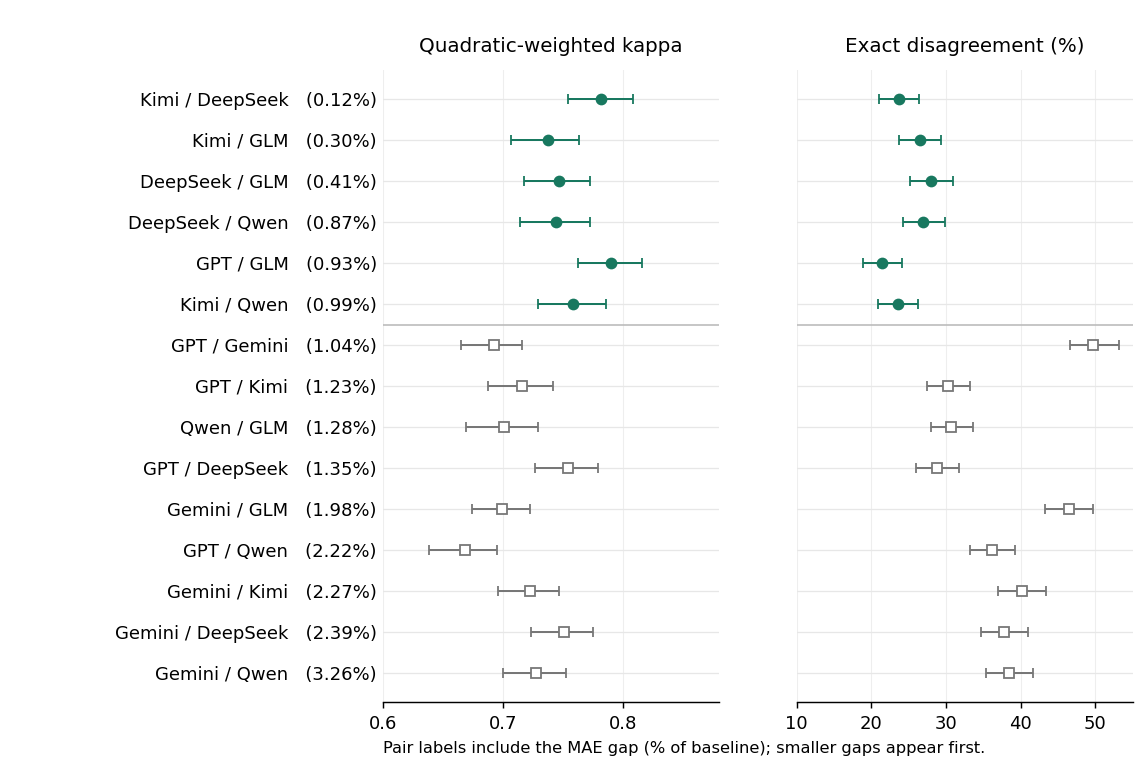

In [4]:
v = agreement.loc[agreement.scheme.eq('validation_claim')].sort_values('mae_difference_pct_baseline').copy().reset_index(drop=True)
plt.rcParams.update({'font.family':'DejaVu Sans', 'font.size':10, 'pdf.fonttype':42, 'ps.fonttype':42})
fig, axes = plt.subplots(1, 2, figsize=(8.8, 6.0), sharey=True)
settings = [('quadratic_kappa', 'Quadratic-weighted kappa', 1),
            ('disagreement', 'Exact disagreement (%)', 100)]
for ax, (metric, title, scale) in zip(axes, settings):
    for close, color, marker in [(False, '#777777','s'), (True,'#18785f','o')]:
        sub = v.loc[v.approximately_equivalent.eq(close)]
        ax.errorbar(scale*sub[metric], sub.index,
                    xerr=scale*np.vstack([sub[metric]-sub[metric+'_lo'], sub[metric+'_hi']-sub[metric]]),
                    fmt=marker, color=color, markerfacecolor=color if close else 'white',
                    markersize=5.5, capsize=2.5, elinewidth=1.1, linestyle='none', zorder=3)
    ax.set_title(title, fontsize=11, pad=10)
    ax.set_axisbelow(True)
    ax.grid(axis='y', color='#e7e7e7', linewidth=0.7)
    ax.grid(axis='x', color='#eeeeee', linewidth=0.6)
    ax.spines[['top','right','left']].set_visible(False)
    ax.tick_params(axis='y', length=0)
    ax.axhline(v.approximately_equivalent.sum()-0.5, color='#bbbbbb', linewidth=0.9)
axes[0].set_yticks(range(len(v)), [f'{short[r.model_a]} / {short[r.model_b]}   ({r.mae_difference_pct_baseline:.2f}%)' for r in v.itertuples()], fontsize=10)
axes[0].invert_yaxis()
axes[0].set_xlim(0.60, 0.88)
axes[0].set_xticks([0.60,0.70,0.80])
axes[1].set_xlim(10, 55)
axes[1].set_xticks([10,20,30,40,50])
fig.subplots_adjust(left=0.335, right=0.99, top=0.91, bottom=0.10, wspace=0.23)
fig.text(0.335, 0.035, 'Pair labels include the MAE gap (% of baseline); smaller gaps appear first.', fontsize=9)
figure_path = PAPER / 'figures/performance_vs_disagreement_color.pdf'
figure_path.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(figure_path, metadata={'CreationDate':None, 'ModDate':None})
preview = BytesIO()
fig.savefig(preview, format='png', dpi=130)
plt.close(fig)
display(Image(data=preview.getvalue()))


## Published agreement results

The shared renderer presents the six close-MAE pairs in Table A10 and ranges across all 15 pairs in Table A11. Full weighting and alignment comparisons remain in the CSVs indexed by SUPPLEMENT.md.

**Reports:** §4.2 and Appendix A.6.


In [5]:
vc = agreement.loc[agreement.scheme.eq('validation_claim')]
close = vc.loc[vc.approximately_equivalent]

def range_text(frame, metric, scale=1, digits=2):
    return f'{scale*frame[metric].min():.{digits}f}--{scale*frame[metric].max():.{digits}f}'

results = r'''% Generated by s5_agreement_diagnostics.ipynb.
For H3(a), six pairs fall within the illustrative 1\% MAE tolerance. On the same 1,039 validation claims, their quadratic-weighted kappa is KAPPA, modal-label disagreement is DISAGREE\%, and mean ordinal distance is DISTANCE categories (Figure~\ref{fig:performance-disagreement}). This is substantial ordinal concordance alongside positive raw disagreement. Appendix~\ref{app:agreement-diagnostics} summarizes population and weighting checks; complete pairwise intervals and alignment diagnostics remain in the repository supplement.
'''
results = (results.replace('KAPPA', range_text(close,'quadratic_kappa'))
           .replace('DISAGREE',range_text(close,'disagreement',100,1))
           .replace('DISTANCE',range_text(close,'mean_ordinal_distance',1,3)))
assert shifts.shift_b_to_a.eq(0).all(), 'Update the generated interpretation if a nonzero shift is selected.'
update_section(PAPER / 'manuscript_body.tex', 'agreement_results', results)

write_primary_appendix(PAPER, 'agreement_analysis')


## Same-model agreement as a fixed-input reference (Experiment 2)

The original experiment sampled 1,000 unique descriptions without replacement (seed 20260813), partitioned them into 50 batches of 20, and held membership, order, and prompt text fixed across all six models and five runs. The frozen audit establishes one prompt hash per batch over its 30 model/run responses. This avoids the changing context of Experiment 1's randomized batches.

We calculate the same three metrics for each of the 60 within-model run pairs (six models × ten unordered pairs) and 375 between-model run pairs (15 model pairs × 25 run combinations), all on these same 1,000 descriptions. A reported kappa is the **arithmetic mean of run-pair kappas**, each with its own marginals, not kappa computed after pooling contingency tables. Each model or model pair has equal weight in the overall means.

For each model pair, the practical reference is the average of its two models' within-model metrics; the corresponding cross-model metrics average all 25 run combinations. Shared 2,000 bootstrap draws resample the 50 fixed batches, retaining all 20 descriptions and every model/run together. Intervals are pointwise 95% percentile intervals, conditional on these five saved runs and hosted endpoints. They capture sample/batch uncertainty, not uncertainty from drawing new inference runs. These run-level fixed-sample estimands differ from Figure 1's modal-label validation comparisons. An independent human or conventional NLP reference remains future work; rerun agreement is not semantic accuracy.

**Reports:** §4.4; Appendix A.4, Table A6.


In [6]:
fixed = read_frozen('data/results/classifications_fixed.csv')
fixed_manifest = read_frozen('data/results/fixed_batch_manifest.csv').sort_values('fixed_position')
prompt_audit = read_frozen('tables/fixed_batch_prompt_audit.csv')
pd.DataFrame(input_manifest).to_csv(OUT / 'input_manifest.csv', index=False)
assert len(fixed) == 30000 and len(fixed_manifest) == 1000
assert not fixed.duplicated(['model','run','description_id']).any()
assert fixed['experiment'].eq('fixed_batch').all()
assert fixed['label_value'].isin(LEVELS).all()
assert set(fixed.model) == set(models) and set(fixed.run) == set(range(1,6))
assert fixed_manifest.description_id.is_unique
assert fixed_manifest.groupby('batch_id').size().eq(20).all()
assert len(prompt_audit) == 50 and prompt_audit.batch_id.is_unique
assert prompt_audit.prompt_hashes.eq(1).all() and prompt_audit.logical_responses.eq(30).all()
assert set(prompt_audit.batch_id) == set(fixed_manifest.batch_id)
positions = fixed.merge(fixed_manifest[['description_id','batch_id','position_in_batch']],
                        on='description_id', suffixes=('','_expected'), validate='many_to_one')
assert positions.batch_id.eq(positions.batch_id_expected).all()
assert positions.position_in_batch.eq(positions.position_in_batch_expected).all()
fixed_wide = fixed.pivot(index='description_id', columns=['model','run'], values='label_value').loc[fixed_manifest.description_id]
assert fixed_wide.shape == (1000,30) and fixed_wide.notna().all().all()
batch_index = pd.Categorical(fixed_manifest.batch_id, categories=sorted(fixed_manifest.batch_id.unique())).codes.astype(np.int64)
fixed_specs = []
for model in models:
    for run_a,run_b in combinations(range(1,6),2):
        fixed_specs.append(dict(kind='within', model_a=model, model_b=model, run_a=run_a, run_b=run_b))
for pair in pairs.itertuples():
    for run_a in range(1,6):
        for run_b in range(1,6):
            fixed_specs.append(dict(kind='between', model_a=pair.model_a, model_b=pair.model_b,
                                    run_a=run_a, run_b=run_b))
fixed_specs = pd.DataFrame(fixed_specs)
assert fixed_specs.kind.value_counts().to_dict() == {'between':375,'within':60}
batch_tables = []
for spec in fixed_specs.itertuples():
    a=fixed_wide[(spec.model_a,spec.run_a)].to_numpy(int)
    b=fixed_wide[(spec.model_b,spec.run_b)].to_numpy(int)
    cell=(a-1)*5+b-1
    batch_tables.append(np.bincount(batch_index*25+cell,minlength=50*25).reshape(50,5,5))
batch_tables=np.stack(batch_tables,axis=1).astype(float)  # batch, run comparison, label A, label B
assert batch_tables.shape == (50,435,5,5)
assert np.all(batch_tables.sum(axis=(-1,-2)) == 20)
FIXED_METRICS=['quadratic_kappa','exact_agreement','mean_ordinal_distance']
def fixed_metrics(c):
    p=c/c.sum(axis=(-1,-2),keepdims=True)
    obs=np.sum(p*QUADRATIC,axis=(-1,-2))
    exp=np.einsum('...i,ij,...j->...',p.sum(axis=-1),QUADRATIC,p.sum(axis=-2))
    return np.stack([1-obs/exp,np.trace(p,axis1=-2,axis2=-1),np.sum(p*DISTANCE,axis=(-1,-2))],axis=-1)
fixed_point=fixed_metrics(batch_tables.sum(axis=0))
batch_rng=np.random.default_rng(20261106)
batch_draws=batch_rng.multinomial(50,np.full(50,1/50),size=N_BOOT)
fixed_boot=np.empty((N_BOOT,len(fixed_specs),len(FIXED_METRICS)))
for start in range(0,N_BOOT,100):
    count_tables=(batch_draws[start:start+100] @ batch_tables.reshape(50,-1)).reshape(-1,435,5,5)
    fixed_boot[start:start+100]=fixed_metrics(count_tables)
assert np.isfinite(fixed_boot).all()

# Independently check every run-pair metric against the unaggregated labels.
for i,spec in enumerate(fixed_specs.itertuples()):
    a=fixed_wide[(spec.model_a,spec.run_a)].to_numpy(int)
    b=fixed_wide[(spec.model_b,spec.run_b)].to_numpy(int)
    assert np.isclose(fixed_point[i,0],cohen_kappa_score(a,b,labels=LEVELS,weights='quadratic'))
    assert np.isclose(fixed_point[i,1],np.mean(a==b))
    assert np.isclose(fixed_point[i,2],np.mean(abs(a-b)))
    # Check one literal batch-cluster resample for each run comparison.
    literal=np.repeat(np.arange(1000),batch_draws[0,batch_index])
    check=fixed_metrics(contingency(a[literal],b[literal],np.ones(len(literal))))
    assert np.allclose(check,fixed_boot[0,i],atol=1e-12)
for j,metric in enumerate(FIXED_METRICS):
    fixed_specs[metric]=fixed_point[:,j]
    fixed_specs[metric+'_lo'],fixed_specs[metric+'_hi']=np.quantile(fixed_boot[:,:,j],[0.025,0.975],axis=0)
fixed_specs.to_csv(OUT/'fixed_input_agreement_by_run_pair.csv',index=False)


### Summarize the fixed-input benchmark

**Reports:** §4.4 and Table A6; pair-specific contrasts use the same batch draws.


In [7]:
def summarize_fixed(name, mask):
    idx=np.flatnonzero(mask)
    point=fixed_point[idx].mean(axis=0)
    draws=fixed_boot[:,idx,:].mean(axis=1)
    row=dict(comparison=name,run_pairs=len(idx))
    for j,metric in enumerate(FIXED_METRICS):
        row[metric]=point[j]
        row[metric+'_lo'],row[metric+'_hi']=np.quantile(draws[:,j],[0.025,0.975])
    return row,draws

summary_rows=[]
for model in models:
    row,_=summarize_fixed(model,fixed_specs.kind.eq('within') & fixed_specs.model_a.eq(model))
    summary_rows.append(row)
within_row,within_boot=summarize_fixed('All models: within',fixed_specs.kind.eq('within'))
between_row,between_boot=summarize_fixed('Different models: between',fixed_specs.kind.eq('between'))
summary_rows.extend([within_row,between_row])
fixed_summary=pd.DataFrame(summary_rows)
fixed_summary.to_csv(OUT/'fixed_input_agreement_reference.csv',index=False)
assert np.isclose(within_row['exact_agreement'],0.8954333333333333)
assert np.isclose(between_row['exact_agreement'],0.65424)
assert np.isclose(within_row['mean_ordinal_distance'],0.1054333333333333)
assert np.isclose(between_row['mean_ordinal_distance'],0.3544986666666667)

contrast_rows=[]
for pair in pairs.itertuples():
    between_mask=(fixed_specs.kind.eq('between') & fixed_specs.model_a.eq(pair.model_a) & fixed_specs.model_b.eq(pair.model_b))
    within_mask=(fixed_specs.kind.eq('within') & fixed_specs.model_a.isin([pair.model_a,pair.model_b]))
    cross,cross_boot=summarize_fixed('cross',between_mask)
    reference,reference_boot=summarize_fixed('reference',within_mask)
    row=dict(pair_id=pair.pair_id,model_a=pair.model_a,model_b=pair.model_b)
    for j,metric in enumerate(FIXED_METRICS):
        row['within_reference_'+metric]=reference[metric]
        row['between_'+metric]=cross[metric]
        row['between_'+metric+'_lo']=cross[metric+'_lo']
        row['between_'+metric+'_hi']=cross[metric+'_hi']
        row['between_minus_within_'+metric]=cross[metric]-reference[metric]
        row['between_minus_within_'+metric+'_lo'],row['between_minus_within_'+metric+'_hi']=np.quantile(cross_boot[:,j]-reference_boot[:,j],[0.025,0.975])
    contrast_rows.append(row)
fixed_contrasts=pd.DataFrame(contrast_rows)
fixed_contrasts.to_csv(OUT/'fixed_input_between_vs_own_rerun.csv',index=False)
overall_contrast={}
for j,metric in enumerate(FIXED_METRICS):
    overall_contrast[metric]=between_row[metric]-within_row[metric]
    overall_contrast[metric+'_lo'],overall_contrast[metric+'_hi']=np.quantile(between_boot[:,j]-within_boot[:,j],[0.025,0.975])
ratio=between_row['mean_ordinal_distance']/within_row['mean_ordinal_distance']
ratio_lo,ratio_hi=np.quantile(between_boot[:,2]/within_boot[:,2],[0.025,0.975])
pd.DataFrame([dict(comparison='Between minus within',**overall_contrast,
                   distance_ratio=ratio,distance_ratio_lo=ratio_lo,distance_ratio_hi=ratio_hi)]).to_csv(OUT/'fixed_input_overall_contrast.csv',index=False)
assert fixed_contrasts['between_minus_within_quadratic_kappa_hi'].lt(0).all()
assert fixed_contrasts['between_minus_within_exact_agreement_hi'].lt(0).all()
assert fixed_contrasts['between_minus_within_mean_ordinal_distance_lo'].gt(0).all()
display(fixed_summary.round(4))
display(fixed_contrasts[['model_a','model_b','within_reference_quadratic_kappa','between_quadratic_kappa',
                         'within_reference_exact_agreement','between_exact_agreement']].round(4))
print('PASS: 435 independent metric checks and literal batch-resampling checks; all 15 cross-model pairs are less concordant than their own rerun reference.')


,comparison,run_pairs,quadratic_kappa,quadratic_kappa_lo,quadratic_kappa_hi,exact_agreement,exact_agreement_lo,exact_agreement_hi,mean_ordinal_distance,mean_ordinal_distance_lo,mean_ordinal_distance_hi
0,GPT-5.6 Sol,10,0.8685,0.8463,0.8900,0.8666,0.8431,0.8899,0.1342,0.1106,0.1578
1,Gemini 3.1 Pro,10,0.9492,0.9356,0.9621,0.9182,0.8948,0.9404,0.0818,0.0596,0.1052
2,Kimi K2.6,10,0.8880,0.8649,0.9091,0.8821,0.8591,0.9043,0.1182,0.0960,0.1412
3,DeepSeek V4 Pro,10,0.9024,0.8798,0.9224,0.8878,0.8608,0.9106,0.1134,0.0904,0.1406
4,Qwen3.5 397B,10,0.9424,0.9220,0.9606,0.9453,0.9275,0.9618,0.0566,0.0394,0.0754
5,GLM-5.2,10,0.8767,0.8574,0.8974,0.8726,0.8520,0.8936,0.1284,0.1070,0.1490
6,All models: within,60,0.9045,0.8935,0.9144,0.8954,0.8842,0.9061,0.1054,0.0946,0.1168
7,Different models: between,375,0.6929,0.6717,0.7125,0.6542,0.6356,0.6721,0.3545,0.3354,0.3743


,model_a,model_b,within_reference_quadratic_kappa,between_quadratic_kappa,within_reference_exact_agreement,between_exact_agreement
0,GPT-5.6 Sol,Gemini 3.1 Pro,0.9089,0.6771,0.8924,0.5620
1,GPT-5.6 Sol,Kimi K2.6,0.8782,0.6688,0.8744,0.6561
2,GPT-5.6 Sol,DeepSeek V4 Pro,0.8854,0.6827,0.8772,0.6582
3,GPT-5.6 Sol,Qwen3.5 397B,0.9054,0.6550,0.9059,0.6411
4,GPT-5.6 Sol,GLM-5.2,0.8726,0.7162,0.8696,0.7192
5,Gemini 3.1 Pro,Kimi K2.6,0.9186,0.7201,0.9002,0.6408
6,Gemini 3.1 Pro,DeepSeek V4 Pro,0.9258,0.7021,0.9030,0.6140
7,Gemini 3.1 Pro,Qwen3.5 397B,0.9458,0.7038,0.9317,0.6325
8,Gemini 3.1 Pro,GLM-5.2,0.9130,0.6512,0.8954,0.5392
9,Kimi K2.6,DeepSeek V4 Pro,0.8952,0.7328,0.8850,0.7260


PASS: 435 independent metric checks and literal batch-resampling checks; all 15 cross-model pairs are less concordant than their own rerun reference.


In [8]:
fixed_results = r'''% Generated by s5_agreement_diagnostics.ipynb.
On Experiment 2's fixed-input panel, mean quadratic-weighted kappa is WITHIN_KAPPA within models versus BETWEEN_KAPPA between models; exact agreement is WITHIN_EXACT\% versus BETWEEN_EXACT\%, and mean ordinal distance is WITHIN_DISTANCE versus BETWEEN_DISTANCE categories (RATIO times as large). Every model has positive rerun disagreement, consistent with H2, and all 15 pairs have greater cross-model than own-rerun ordinal distance, consistent with H1. Paired batch-bootstrap intervals for the latter excess exclude zero. Appendix~\ref{app:fixed-reference} gives per-model estimates, run pairing, and intervals. These are run-level repeatability comparisons, not semantic-accuracy or operational-harm thresholds.
'''
fixed_results=(fixed_results.replace('WITHIN_KAPPA',f'{within_row["quadratic_kappa"]:.3f}')
               .replace('BETWEEN_KAPPA',f'{between_row["quadratic_kappa"]:.3f}')
               .replace('WITHIN_EXACT',f'{100*within_row["exact_agreement"]:.2f}')
               .replace('BETWEEN_EXACT',f'{100*between_row["exact_agreement"]:.2f}')
               .replace('WITHIN_DISTANCE',f'{within_row["mean_ordinal_distance"]:.3f}')
               .replace('BETWEEN_DISTANCE',f'{between_row["mean_ordinal_distance"]:.3f}')
               .replace('RATIO',f'{ratio:.1f}'))
update_section(PAPER / 'manuscript_body.tex', 'fixed_input_results', fixed_results)

write_primary_appendix(PAPER, 'fixed_input_analysis')
print(fixed_results)


% Generated by s5_agreement_diagnostics.ipynb.
On Experiment 2's fixed-input panel, mean quadratic-weighted kappa is 0.905 within models versus 0.693 between models; exact agreement is 89.54\% versus 65.42\%, and mean ordinal distance is 0.105 versus 0.354 categories (3.4 times as large). Every model has positive rerun disagreement, consistent with H2, and all 15 pairs have greater cross-model than own-rerun ordinal distance, consistent with H1. Paired batch-bootstrap intervals for the latter excess exclude zero. Appendix~\ref{app:fixed-reference} gives per-model estimates, run pairing, and intervals. These are run-level repeatability comparisons, not semantic-accuracy or operational-harm thresholds.



## Illustrative two-track routing on validation claims

Apply the illustrative rule to each model's **original five-run modal labels**: negligible/low/medium (1–3) go to straight-through processing (STP), and high/catastrophic (4–5) are referred to a senior adjuster. Each of the 1,039 validation claims counts once, including claims sharing a description. No GLM prediction, new inference, or fitted routing model is involved.

Report counts and realized paid loss in both tracks for each model. For all 15 replacements A→B, distinguish STP→referral and referral→STP switches, with counts and paid-loss amounts in each direction. The six close-performance pairs use the original 1% MAE rule. Dollar amounts are summed in integer cents to check exact conservation; they are historical payments associated with claims, **not costs or savings caused by a handling decision**.

For context, also report STP claims whose realized payment exceeds the original training-loss 80th percentile. This existing training-only payment anchor is a retrospective large-payment flag, not a correct-route label or a new economic acceptance threshold. Without adjudicated routing needs, handling costs, or verified description timing, neither these claims nor all loss assigned to STP can be called handling errors. This is a descriptive illustration on the validation sample; no uncertainty or causal-cost model is added.

**Reports:** §4.2; Appendix A.7, Tables A12–A13.


In [9]:
routing_labels=labels.loc[valid.description_id,models].to_numpy(int)
routing_referral=routing_labels>=4
routing_cents=np.rint(valid.Loss.to_numpy()*100).astype(np.int64)
assert np.allclose(routing_cents/100,valid.Loss.to_numpy(),rtol=0,atol=1e-8)
routing_total_cents=int(routing_cents.sum())
large_payment_threshold=float(claims.loc[claims.split.eq('train'),'Loss'].quantile(.8))
large_payment=valid.Loss.to_numpy()>large_payment_threshold
track_rows=[];claim_rows=[]
for j,model in enumerate(models):
    ref=routing_referral[:,j]
    for track,mask in [('straight_through',~ref),('senior_referral',ref)]:
        cents=int(routing_cents[mask].sum())
        large=mask & large_payment
        track_rows.append(dict(model=model,track=track,claims=int(mask.sum()),
                               claim_share=float(mask.mean()),paid_loss=cents/100,
                               paid_loss_share=cents/routing_total_cents,
                               above_training_q80_claims=int(large.sum()),
                               above_training_q80_paid_loss=int(routing_cents[large].sum())/100,
                               training_q80=large_payment_threshold))
    frame=pd.DataFrame(dict(claim_row=valid.index.to_numpy(),description_id=valid.description_id.to_numpy(),
                            model=model,modal_label_value=routing_labels[:,j],
                            track=np.where(ref,'senior_referral','straight_through'),
                            paid_loss=routing_cents/100,above_training_q80=large_payment))
    claim_rows.append(frame)
routing_tracks=pd.DataFrame(track_rows)
routing_claims=pd.concat(claim_rows,ignore_index=True)
routing_pair_rows=[]
for pair in pairs.itertuples():
    ia,ib=models.index(pair.model_a),models.index(pair.model_b)
    a,b=routing_referral[:,ia],routing_referral[:,ib]
    up=(~a)&b
    down=a&(~b)
    switched=a!=b
    assert np.array_equal(switched,up|down) and not np.any(up&down)
    assert int(b.sum())-int(a.sum())==int(up.sum())-int(down.sum())
    assert int(routing_cents[b].sum())-int(routing_cents[a].sum())==int(routing_cents[up].sum())-int(routing_cents[down].sum())
    cents=int(routing_cents[switched].sum())
    routing_pair_rows.append(dict(model_a=pair.model_a,model_b=pair.model_b,
                                  close_mae_pair=pair.approximately_equivalent,
                                  switched_claims=int(switched.sum()),switched_claim_share=float(switched.mean()),
                                  switched_paid_loss=cents/100,switched_paid_loss_share=cents/routing_total_cents,
                                  stp_to_referral_claims=int(up.sum()),stp_to_referral_paid_loss=int(routing_cents[up].sum())/100,
                                  referral_to_stp_claims=int(down.sum()),referral_to_stp_paid_loss=int(routing_cents[down].sum())/100))
routing_pairs=pd.DataFrame(routing_pair_rows)
assert len(routing_tracks)==12 and len(routing_pairs)==15 and len(routing_claims)==6*1039
assert routing_tracks.groupby('model').claims.sum().eq(1039).all()
assert np.allclose(routing_tracks.groupby('model').paid_loss.sum(),routing_total_cents/100)
assert not routing_claims.duplicated(['claim_row','model']).any()
for model in models:
    expected=routing_claims.loc[routing_claims.model.eq(model)].groupby('track').agg(claims=('paid_loss','size'),paid_loss=('paid_loss','sum'))
    observed=routing_tracks.loc[routing_tracks.model.eq(model)].set_index('track')
    assert np.array_equal(expected.claims,observed.loc[expected.index,'claims'])
    assert np.allclose(expected.paid_loss,observed.loc[expected.index,'paid_loss'])
routing_tracks.to_csv(OUT/'illustrative_routing_by_model.csv',index=False)
routing_pairs.to_csv(OUT/'illustrative_routing_pair_switches.csv',index=False)
routing_claims.to_csv(OUT/'illustrative_routing_claims.csv',index=False)


### Render the routing illustration

**Reports:** §4.2 and Tables A12–A13; retain full pairwise results in the CSVs.


In [10]:
selected_routing=routing_pairs.loc[routing_pairs.close_mae_pair]
example_routing=routing_pairs.loc[routing_pairs.model_a.eq('Kimi K2.6') & routing_pairs.model_b.eq('Qwen3.5 397B')].iloc[0]
example_a=routing_tracks.loc[routing_tracks.model.eq('Kimi K2.6') & routing_tracks.track.eq('senior_referral')].iloc[0]
example_b=routing_tracks.loc[routing_tracks.model.eq('Qwen3.5 397B') & routing_tracks.track.eq('senior_referral')].iloc[0]
brief=(
    'An illustrative label-based rule sends negligible, low, and medium modal labels to straight-through processing '
    'and high or catastrophic labels to a senior adjuster (Appendix~\\ref{app:illustrative-routing}). '
    f'Across the six close-MAE pairs, {selected_routing.switched_claims.min()}--{selected_routing.switched_claims.max()} '
    f'of 1,039 claims ({100*selected_routing.switched_claim_share.min():.1f}--{100*selected_routing.switched_claim_share.max():.1f}\\%) '
    'switch tracks. Kimi and Qwen refer '
    f'{example_a.claims} and {example_b.claims} claims, respectively, yet '
    f'{example_routing.switched_claims} switch tracks, carrying '
    f'\\${example_routing.switched_paid_loss/1e6:.2f} million '
    f'({100*example_routing.switched_paid_loss_share:.1f}\\%) of validation paid loss. '
    'These are allocations of historical payments, not costs caused by routing or demonstrated handling errors.\n'
)
update_section(PAPER/'manuscript_body.tex','illustrative_routing_results',brief)

write_primary_appendix(PAPER, 'illustrative_routing_analysis')
display(routing_tracks.round(4))
display(routing_pairs.round(4))
print(brief)
print('Verified exact claim/payment conservation and both directional switches for all 15 model replacements. No new inference or GLM fits.')


,model,track,claims,claim_share,paid_loss,paid_loss_share,above_training_q80_claims,above_training_q80_paid_loss,training_q80
0,GPT-5.6 Sol,straight_through,889,0.8556,8518244.45,0.3815,166,6768877.22,9002.77
1,GPT-5.6 Sol,senior_referral,150,0.1444,13808175.08,0.6185,100,13585560.00,9002.77
2,Gemini 3.1 Pro,straight_through,918,0.8835,8960318.14,0.4013,183,7157906.42,9002.77
3,Gemini 3.1 Pro,senior_referral,121,0.1165,13366101.39,0.5987,83,13196530.80,9002.77
4,Kimi K2.6,straight_through,980,0.9432,12354669.78,0.5534,221,10436669.27,9002.77
5,Kimi K2.6,senior_referral,59,0.0568,9971749.75,0.4466,45,9917767.95,9002.77
6,DeepSeek V4 Pro,straight_through,935,0.8999,10085145.45,0.4517,195,8257242.37,9002.77
7,DeepSeek V4 Pro,senior_referral,104,0.1001,12241274.08,0.5483,71,12097194.85,9002.77
8,Qwen3.5 397B,straight_through,982,0.9451,15120394.23,0.6772,224,13202672.25,9002.77
9,Qwen3.5 397B,senior_referral,57,0.0549,7206025.30,0.3228,42,7151764.97,9002.77


,model_a,model_b,close_mae_pair,switched_claims,switched_claim_share,switched_paid_loss,switched_paid_loss_share,stp_to_referral_claims,stp_to_referral_paid_loss,referral_to_stp_claims,referral_to_stp_paid_loss
0,GPT-5.6 Sol,Gemini 3.1 Pro,False,61,0.0587,1442010.63,0.0646,16,499968.47,45,942042.16
1,GPT-5.6 Sol,Kimi K2.6,False,95,0.0914,3948660.11,0.1769,2,56117.39,93,3892542.72
2,GPT-5.6 Sol,DeepSeek V4 Pro,False,84,0.0808,2303273.02,0.1032,19,368186.01,65,1935087.01
3,GPT-5.6 Sol,Qwen3.5 397B,False,101,0.0972,6618257.64,0.2964,4,8053.93,97,6610203.71
4,GPT-5.6 Sol,GLM-5.2,True,78,0.0751,2627691.25,0.1177,34,1106378.38,44,1521312.87
5,Gemini 3.1 Pro,Kimi K2.6,False,80,0.0770,3648816.42,0.1634,9,127232.39,71,3521584.03
6,Gemini 3.1 Pro,DeepSeek V4 Pro,False,73,0.0703,2025081.39,0.0907,28,450127.04,45,1574954.35
7,Gemini 3.1 Pro,Qwen3.5 397B,False,80,0.0770,6244229.21,0.2797,8,42076.56,72,6202152.65
8,Gemini 3.1 Pro,GLM-5.2,False,75,0.0722,2031443.86,0.0910,47,1029291.53,28,1002152.33
9,Kimi K2.6,DeepSeek V4 Pro,True,59,0.0568,2766984.63,0.1239,52,2518254.48,7,248730.15


An illustrative label-based rule sends negligible, low, and medium modal labels to straight-through processing and high or catastrophic labels to a senior adjuster (Appendix~\ref{app:illustrative-routing}). Across the six close-MAE pairs, 38--90 of 1,039 claims (3.7--8.7\%) switch tracks. Kimi and Qwen refer 59 and 57 claims, respectively, yet 38 switch tracks, carrying \$5.92 million (26.5\%) of validation paid loss. These are allocations of historical payments, not costs caused by routing or demonstrated handling errors.

Verified exact claim/payment conservation and both directional switches for all 15 model replacements. No new inference or GLM fits.


In [11]:
environment = dict(python=platform.python_version(), numpy=np.__version__, pandas=pd.__version__,
                   scipy=scipy.__version__, sklearn=sklearn.__version__, matplotlib=matplotlib.__version__,
                   bootstrap_replicates=N_BOOT, bootstrap_seed=SEED, fixed_input_bootstrap_seed=20261106, fixed_input_bootstrap_unit="20-description batch")
(OUT / 'environment.json').write_text(json.dumps(environment, indent=2)+'\n')
artifacts = [p for p in sorted(OUT.iterdir()) if p.is_file() and p.name != 'artifact_manifest.csv']
artifacts += [figure_path]
pd.DataFrame([dict(path=str(p.relative_to(ROOT)), bytes=p.stat().st_size,
                   sha256=hashlib.sha256(p.read_bytes()).hexdigest()) for p in artifacts]).to_csv(OUT / 'artifact_manifest.csv', index=False)
print('Modal-label and fixed-input reference results generated.')
print(f'Verified all 60 pair/population combinations; wrote {len(artifacts)} reproducibility artifacts. No inference requests made.')


Modal-label and fixed-input reference results generated.
Verified all 60 pair/population combinations; wrote 16 reproducibility artifacts. No inference requests made.
